                                     SARIMAX Results                                      
Dep. Variable:                                  y   No. Observations:                35078
Model:             SARIMAX(1, 0, 1)x(0, 1, 1, 24)   Log Likelihood              -45475.397
Date:                            Sat, 20 Jun 2026   AIC                          90976.794
Time:                                    02:18:33   BIC                          91086.824
Sample:                                01-01-2020   HQIC                         91011.840
                                     - 01-01-2024                                         
Covariance Type:                              opg                                         
                              coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------
PM10                        1.6454      0.015    112.268      0.000       1.617       1.

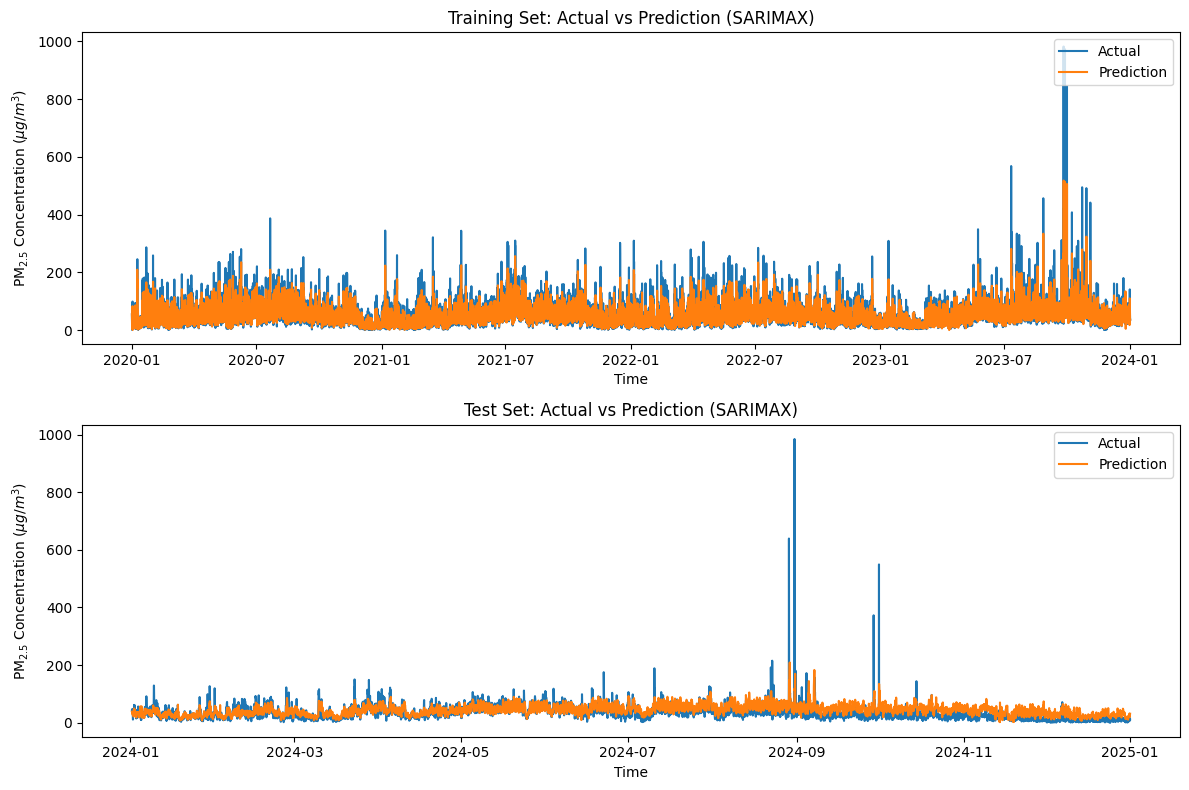

Fitting 5 folds for each of 30 candidates, totalling 150 fits
[LightGBM] [Warning] feature_fraction is set=0.6, colsample_bytree=1.0 will be ignored. Current value: feature_fraction=0.6
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Warning] feature_fraction is set=0.6, colsample_bytree=1.0 will be ignored. Current value: feature_fraction=0.6
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.003650 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2550
[LightGBM] [Info] Number of data points in the train set: 35077, number of used features: 10
[LightGBM] [Info] Start training from score 51.167608

===== BEST PARAMETERS =====
{'subsample': 0.7, 'reg_lambda': 0.1, 'reg_alpha': 0.02, 'num_leaves': 14, 'n_estimators': 1200, 'min_child_samples': 30, 'max_depth': 9, 'learning_rate': 0.01, 'feature_fraction': 0.6}
[LightGBM] [Warning] feature_fraction is set=0.6, co

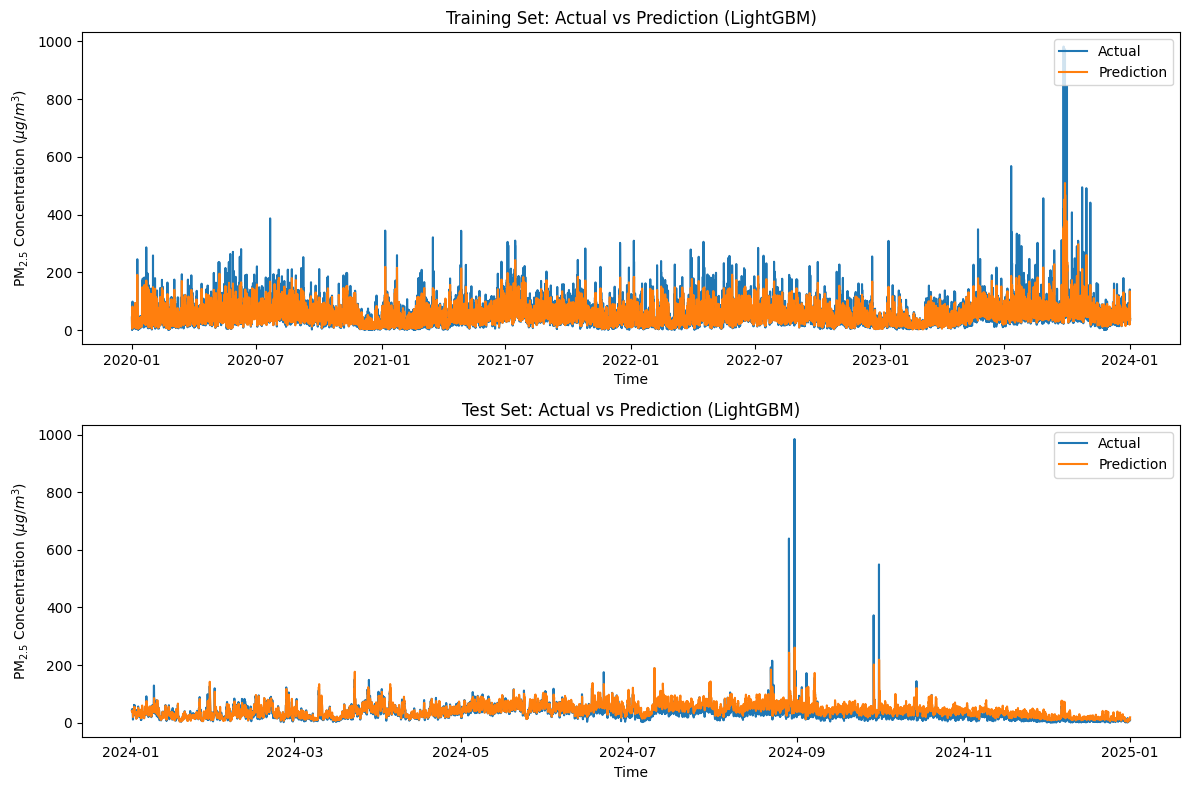

Best alpha (SARIMAX): 0.0
Best beta (LGBM): 1.0

=== TRAIN ENSEMBLE ===
RMSE: 15.339666848620283
MAE : 7.6236150831265945
R2  : 0.8207696834735765

=== TEST ENSEMBLE ===
RMSE: 20.188097223480277
MAE : 12.338520408099146
R2  : 0.36736260006353605


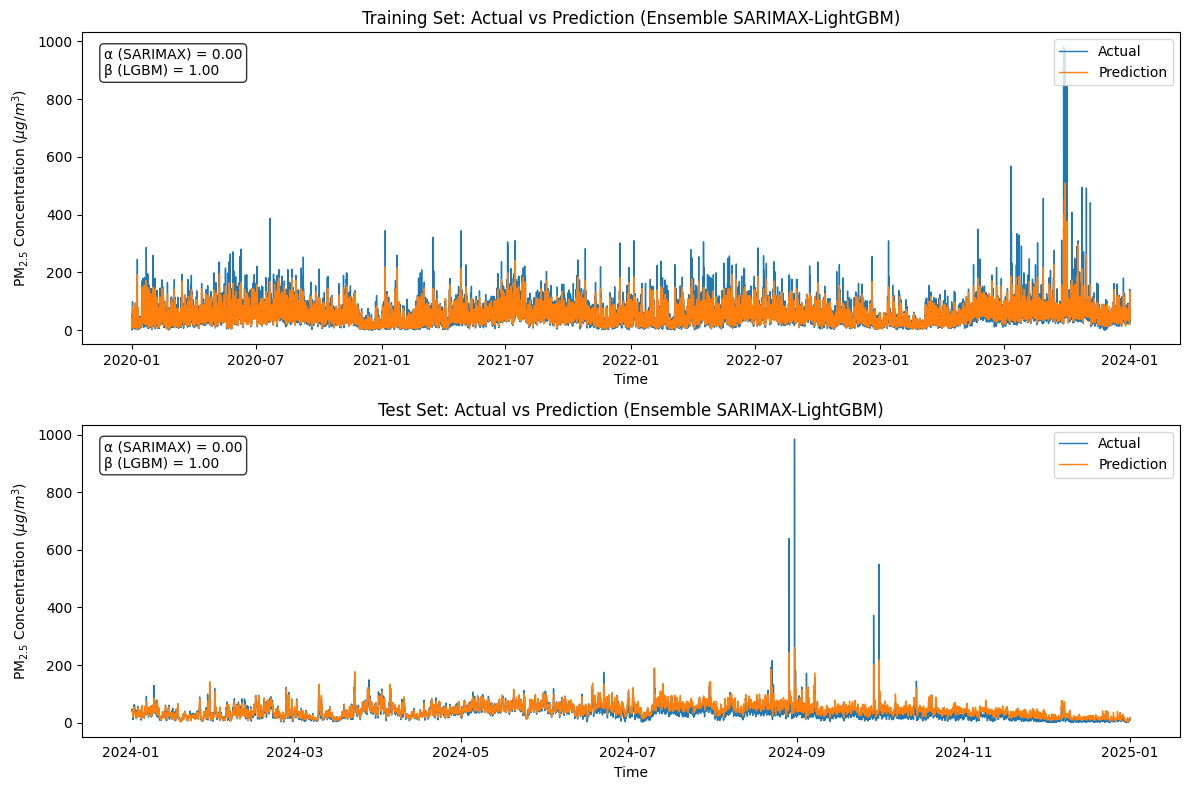

In [ ]:
# ==================================================
# 1. IMPORT LIBRARY
# ==================================================
import pandas as pd
import numpy as np
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.preprocessing import PowerTransformer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings("ignore")


# ==================================================
# 1. LOAD DATA
# ==================================================
df_path = "/content/drive/MyDrive/SARIMAX/Data Imputasi 2/Data Final Konsentrasi Meteorologi DKI4 Lubang Buaya.xlsx"
df = pd.read_excel(df_path, parse_dates=['datetime'], index_col='datetime')

y = df['PM2.5'].values.reshape(-1, 1)

X = df[['PM10','SO2','CO','O3','NO2',
        'Suhu Udara (°C)',
        'Kelembaban Relatif (%)',
        'Kecepatan Angin (m/s)',
        'Radiasi Matahari (W/m²)']]

# ==================================================
# 2. LOG TRANSFORM EKSOGEN
# ==================================================
for col in X.columns:

    min_val = X[col].min()

    # supaya aman jika ada nilai 0 / negatif
    if min_val <= 0:
        shift = abs(min_val) + 1
    else:
        shift = 0

    X[col] = np.log1p(X[col] + shift)

# ==================================================
# 3. TRAIN TEST SPLIT
# ==================================================
train_size = int(len(df) * 0.8)

y_train_raw = y[:train_size]
y_test_raw  = y[train_size:]

exog_train = X.iloc[:train_size]
exog_test  = X.iloc[train_size:]

# ==================================================
# 4. BOX-COX TRANSFORM TARGET
# ==================================================
if np.any(y_train_raw <= 0):
    y_shift = abs(np.min(y_train_raw)) + 1
else:
    y_shift = 0

y_train_pos = y_train_raw + y_shift
y_test_pos  = y_test_raw + y_shift

pt = PowerTransformer(
    method='box-cox',
    standardize=False
)

y_train = pt.fit_transform(y_train_pos)
y_test  = pt.transform(y_test_pos)

# ==================================================
# 5. MODEL SARIMAX
# ==================================================
order = (1, 0, 1)
seasonal_order = (0, 1, 1, 24)

model = SARIMAX(
    y_train.flatten(),
    exog=exog_train,
    order=order,
    seasonal_order=seasonal_order,
    enforce_stationarity=False,
    enforce_invertibility=False
)

result = model.fit(disp=False)
print(result.summary())

# ==================================================
# 6. PREDIKSI
# ==================================================
pred_train = result.predict(
    start=0,
    end=len(y_train)-1,
    exog=exog_train
)

pred_test = result.predict(
    start=len(y_train),
    end=len(y_train)+len(y_test)-1,
    exog=exog_test
)

# ==================================================
# 7. INVERSE BOX-COX
# ==================================================
pred_train_inv = pt.inverse_transform(
    pred_train.to_numpy().reshape(-1, 1)
).flatten() - y_shift

pred_test_inv = pt.inverse_transform(
    pred_test.to_numpy().reshape(-1, 1)
).flatten() - y_shift

y_train_inv = pt.inverse_transform(
    y_train
).flatten() - y_shift

y_test_inv = pt.inverse_transform(
    y_test
).flatten() - y_shift

# ==================================================
# 8. EVALUASI
# ==================================================
def print_metrics(true, pred, label=""):

    mask = ~np.isnan(true) & ~np.isnan(pred)

    true_clean = true[mask]
    pred_clean = pred[mask]

    mae = mean_absolute_error(true_clean, pred_clean)
    rmse = np.sqrt(mean_squared_error(true_clean, pred_clean))
    r2 = r2_score(true_clean, pred_clean)

    print(f"\n===== {label} =====")
    print(f"MAE  : {mae:.4f}")
    print(f"RMSE : {rmse:.4f}")
    print(f"R2   : {r2:.4f}")

print_metrics(y_train_inv, pred_train_inv, "TRAIN")
print_metrics(y_test_inv, pred_test_inv, "TEST")

# =========================
# 8. Plot hasil
# =========================
fig, ax = plt.subplots(2, 1, figsize=(12, 8))

ax[0].plot(df.index[:train_size], y_train_inv, label='Actual')
ax[0].plot(df.index[:train_size], pred_train_inv, label='Prediction')
ax[0].set_title('Training Set: Actual vs Prediction (SARIMAX)')
ax[0].set_ylabel(r'PM$_{2.5}$ Concentration ($\mu g/m^3$)')
ax[0].set_xlabel('Time')
ax[0].legend(loc='upper right')

ax[1].plot(df.index[train_size:], y_test_inv, label='Actual')
ax[1].plot(df.index[train_size:], pred_test_inv, label='Prediction')
ax[1].set_title('Test Set: Actual vs Prediction (SARIMAX)')
ax[1].set_ylabel(r'PM$_{2.5}$ Concentration ($\mu g/m^3$)')
ax[1].set_xlabel('Time')
ax[1].legend(loc='upper right')

plt.tight_layout()
plt.savefig(
    '/content/drive/MyDrive/PDF Gambar/Lubang Buaya/SARIMAX_plot.pdf',
    dpi=600,
    bbox_inches='tight'
)
plt.show()

# =====================================================
# SIMPAN HASIL SARIMAX SEBELUM MASUK KE BLOK SVR
# =====================================================

sarimax_train_pred = pred_train_inv.copy()
sarimax_test_pred  = pred_test_inv.copy()

y_train_actual = y_train_raw.flatten()
y_test_actual  = y_test_raw.flatten()

# ===============================
# 1. IMPORT LIBRARY
# ===============================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from lightgbm import LGBMRegressor

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV

import warnings
warnings.filterwarnings("ignore")


# ===============================
# 2. LOAD DATA
# ===============================
df_path = "/content/drive/MyDrive/SARIMAX/Data Imputasi 2/Data Final Konsentrasi Meteorologi DKI4 Lubang Buaya.xlsx"

df = pd.read_excel(
    df_path,
    parse_dates=['datetime'],
    index_col='datetime'
)

# ===============================
# 3. TARGET & FEATURES
# ===============================
y = df['PM2.5']

X = df[[
    'PM10',
    'SO2',
    'CO',
    'O3',
    'NO2',
    'Suhu Udara (°C)',
    'Kelembaban Relatif (%)',
    'Kecepatan Angin (m/s)',
    'Radiasi Matahari (W/m²)',
]]


# ===============================
# 4. TIME SERIES SPLIT
# ===============================
train_size = int(len(df) * 0.8)

X_train, X_test = X.iloc[:train_size], X.iloc[train_size:]
y_train, y_test = y.iloc[:train_size], y.iloc[train_size:]


# ===============================
# 5. BASE MODEL
# ===============================
lgbm = LGBMRegressor(random_state=42)


# ===============================
# 6. PARAMETER GRID (FIXED)
# ===============================
param_grid = {
    'max_depth': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    'num_leaves': [10, 12, 14, 16, 18, 20],
    'learning_rate': [0.01, 0.02, 0.03, 0.05],
    'n_estimators': [1000, 1200, 1500, 1800, 2000],
    'min_child_samples': [10, 20, 30, 40, 50],
    'subsample': [0.7, 0.8, 0.9],
    'feature_fraction': [0.5, 0.6, 0.7, 0.8, 0.9],
    'reg_alpha': [0.01, 0.02, 0.03, 0.04, 0.05],
    'reg_lambda': [0.1, 0.5, 1]
}


# ===============================
# 7. TIME SERIES CV
# ===============================
tscv = TimeSeriesSplit(n_splits=5)


# ===============================
# 8. RANDOM SEARCH CV
# ===============================
search = RandomizedSearchCV(
    estimator=lgbm,
    param_distributions=param_grid,
    n_iter=30,
    cv=tscv,
    scoring='neg_root_mean_squared_error',
    verbose=2,
    random_state=42,
    n_jobs=-1
)


# ===============================
# 9. TRAIN MODEL
# ===============================
search.fit(X_train, y_train)

best_model = search.best_estimator_

print("\n===== BEST PARAMETERS =====")
print(search.best_params_)


# ===============================
# 10. PREDICTION
# ===============================
lgbm_train_pred = best_model.predict(X_train)
lgbm_test_pred  = best_model.predict(X_test)


# ===============================
# 11. EVALUATION FUNCTION
# ===============================
def evaluate(y_true, y_pred):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    return rmse, mae, r2


train_rmse, train_mae, train_r2 = evaluate(y_train, lgbm_train_pred)
test_rmse, test_mae, test_r2 = evaluate(y_test, lgbm_test_pred)


# ===============================
# 12. RESULT TABLE
# ===============================
hasil = pd.DataFrame({
    'Dataset': ['Train', 'Test'],
    'RMSE': [train_rmse, test_rmse],
    'MAE': [train_mae, test_mae],
    'R2': [train_r2, test_r2]
})

print("\n===== HASIL EVALUASI =====")
print(hasil.round(4))


import matplotlib.pyplot as plt

fig, ax = plt.subplots(2, 1, figsize=(12, 8))

# ================= TRAIN =================
ax[0].plot(y_train.index, y_train, label='Actual')
ax[0].plot(y_train.index, lgbm_train_pred, label='Prediction')

ax[0].set_title('Training Set: Actual vs Prediction (LightGBM)')
ax[0].set_xlabel('Time')
ax[0].set_ylabel(r'PM$_{2.5}$ Concentration ($\mu g/m^3$)')
ax[0].legend(loc='upper right')

# ================= TEST =================
ax[1].plot(y_test.index, y_test, label='Actual')
ax[1].plot(y_test.index, lgbm_test_pred, label='Prediction')

ax[1].set_title('Test Set: Actual vs Prediction (LightGBM)')
ax[1].set_xlabel('Time')
ax[1].set_ylabel(r'PM$_{2.5}$ Concentration ($\mu g/m^3$)')
ax[1].legend(loc='upper right')

plt.tight_layout()
plt.savefig(
    '/content/drive/MyDrive/PDF Gambar/Lubang Buaya/LightGBM_plot.pdf',
    dpi=600,
    bbox_inches='tight'
)
plt.show()

min_train = min(len(sarimax_train_pred), len(lgbm_train_pred))
min_test  = min(len(sarimax_test_pred), len(lgbm_test_pred))

sarimax_train = sarimax_train_pred[:min_train]
lgbm_train    = lgbm_train_pred[:min_train]
y_train_ens   = y_train_actual[:min_train]

sarimax_test  = sarimax_test_pred[:min_test]
lgbm_test     = lgbm_test_pred[:min_test]
y_test_ens    = y_test_actual[:min_test]

from sklearn.metrics import mean_squared_error
import numpy as np

best_rmse = np.inf
best_alpha = 0

for alpha in np.arange(0, 1.01, 0.1):
    beta = 1 - alpha

    pred_train = alpha * sarimax_train + beta * lgbm_train

    rmse = np.sqrt(mean_squared_error(y_train_ens, pred_train))

    if rmse < best_rmse:
        best_rmse = rmse
        best_alpha = alpha

best_beta = 1 - best_alpha

print("Best alpha (SARIMAX):", best_alpha)
print("Best beta (LGBM):", best_beta)

ensemble_train = best_alpha * sarimax_train + best_beta * lgbm_train
ensemble_test  = best_alpha * sarimax_test + best_beta * lgbm_test

from sklearn.metrics import mean_absolute_error, r2_score

def evaluate(y_true, y_pred, label=""):
    print(f"\n=== {label} ===")
    print("RMSE:", np.sqrt(mean_squared_error(y_true, y_pred)))
    print("MAE :", mean_absolute_error(y_true, y_pred))
    print("R2  :", r2_score(y_true, y_pred))

evaluate(y_train_ens, ensemble_train, "TRAIN ENSEMBLE")
evaluate(y_test_ens, ensemble_test, "TEST ENSEMBLE")

# =====================================================
# PLOT ENSEMBLE SARIMAX + LGBM (DENGAN α β)
# =====================================================
train_datetime = X_train.index[:min_train]
test_datetime  = X_test.index[:min_test]

# =====================================================
# PLOT ENSEMBLE SARIMAX + LGBM
# =====================================================

fig, ax = plt.subplots(2, 1, figsize=(12, 8))

textstr = (
    f'α (SARIMAX) = {best_alpha:.2f}\n'
    f'β (LightGBM) = {best_beta:.2f}'
)

# ================= TRAIN =================

ax[0].plot(
    train_index,
    y_train_ens,
    label='Actual',
    linewidth=1
)

ax[0].plot(
    train_index,
    ensemble_train,
    label='Prediction',
    linewidth=1
)

ax[0].set_title(
    'Training Set: Actual vs Prediction (Ensemble SARIMAX-LightGBM)'
)

ax[0].set_ylabel(
    r'PM$_{2.5}$ Concentration ($\mu g/m^3$)'
)

ax[0].set_xlabel('Time')

ax[0].legend(loc='upper right')

ax[0].text(
    0.02,
    0.95,
    textstr,
    transform=ax[0].transAxes,
    fontsize=10,
    verticalalignment='top',
    bbox=dict(
        boxstyle='round',
        facecolor='white',
        alpha=0.8
    )
)

# ================= TEST =================

ax[1].plot(
    test_index,
    y_test_ens,
    label='Actual',
    linewidth=1
)

ax[1].plot(
    test_index,
    ensemble_test,
    label='Prediction',
    linewidth=1
)

ax[1].set_title(
    'Test Set: Actual vs Prediction (Ensemble SARIMAX-LightGBM)'
)

ax[1].set_ylabel(
    r'PM$_{2.5}$ Concentration ($\mu g/m^3$)'
)

ax[1].set_xlabel('Time')

ax[1].legend(loc='upper right')

ax[1].text(
    0.02,
    0.95,
    textstr,
    transform=ax[1].transAxes,
    fontsize=10,
    verticalalignment='top',
    bbox=dict(
        boxstyle='round',
        facecolor='white',
        alpha=0.8
    )
)

# =====================================================
# FINAL LAYOUT
# =====================================================
plt.tight_layout()
plt.savefig(
    '/content/drive/MyDrive/PDF Gambar/Lubang Buaya/Ensemble_SARIMAX_LightGBM_plot.pdf',
    dpi=600,
    bbox_inches='tight'
)
plt.show()